**Setup.** Run this cell first: it locates the data files this notebook reads. On Google
Colab it downloads them (the `Data/` and `Support/` folders) from the book's GitHub
repository; on your computer, run the notebook from the `notebooks/` folder.

In [1]:
import os
import sys
path = ''
if 'google.colab' in sys.modules and not os.path.isdir('Data'):
    if not os.path.isdir('statsbook'):
        os.system('git clone -q --depth 1 --filter=blob:none --sparse '
                  'https://github.com/vzavala/StatsBook-GitBook.git statsbook')
        os.system('git -C statsbook sparse-checkout set notebooks/Data notebooks/Support')
    path = 'statsbook/notebooks/'

Subdomains (events) for the Gibbs reactor data (Victor Z, UW-Madison, 2024).
Realizations $x_\omega=(x_{\omega,1},x_{\omega,2})$ of pressure $X_1$ (`x1`) and conversion
$X_2$ (`x2`). Each panel shades an event $\mathcal{A}=\mathcal{R}\cap\mathcal{D}$:
an "and" event, a narrower "and" event, an "or" event ($\mathcal{R}_1\cup\mathcal{R}_2$),
and an impossible event (empty set).

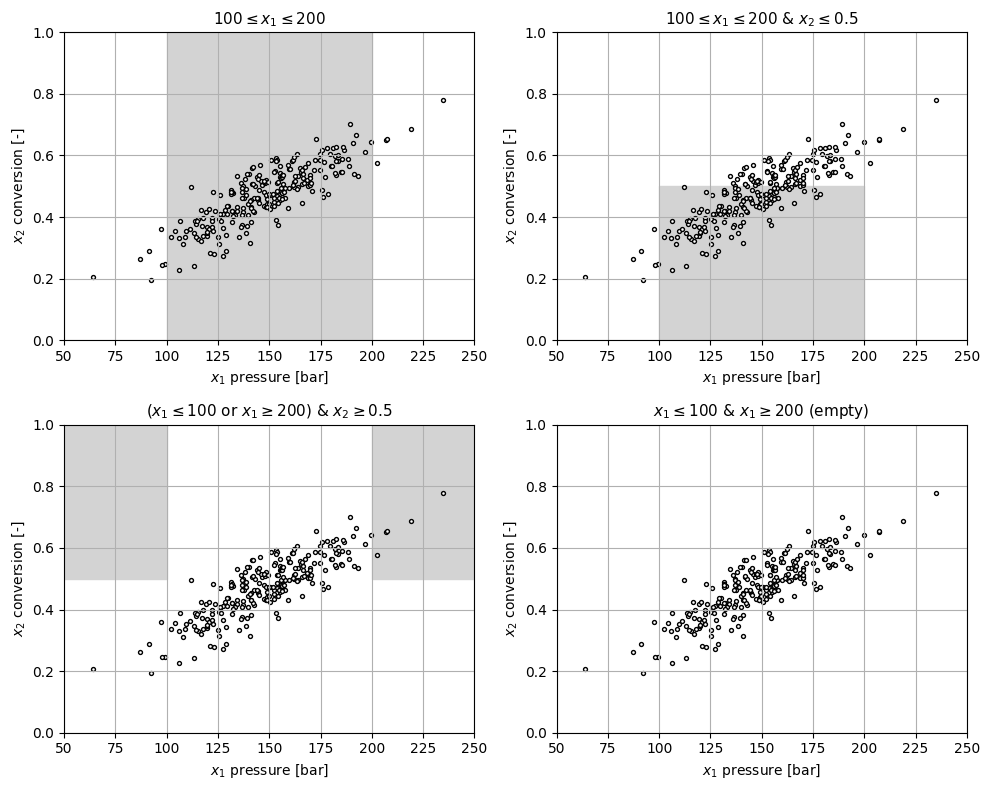

In [2]:
import numpy as np
import matplotlib.pyplot as plt

data = np.loadtxt(path+'Data/gibbs_hightemp_class.dat')
S = len(data)
np.random.seed(1)
x1 = data[:, 1] + np.random.normal(0, 1, S)       # pressure [bar]
x2 = data[:, 2] + np.random.normal(0, 0.05, S)    # conversion [-]

events = [
    ("$100\\leq x_1\\leq 200$", [((100, 200), (0, 1))]),
    ("$100\\leq x_1\\leq 200$ & $x_2\\leq 0.5$", [((100, 200), (0, 0.5))]),
    ("($x_1\\leq 100$ or $x_1\\geq 200$) & $x_2\\geq 0.5$", [((0, 100), (0.5, 1)), ((200, 250), (0.5, 1))]),
    ("$x_1\\leq 100$ & $x_1\\geq 200$ (empty)", []),
]
fig, axs = plt.subplots(2, 2, figsize=(10, 8))
for ax, (title, boxes) in zip(axs.ravel(), events):
    for (a1, b1), (a2, b2) in boxes:
        ax.fill_between([a1, b1], a2, b2, color='lightgrey')
    ax.scatter(x1, x2, s=8, color='black', facecolors='white')
    ax.set_title(title, fontsize=11)
    ax.set_xlabel('$x_1$ pressure [bar]')
    ax.set_ylabel('$x_2$ conversion [-]')
    ax.axis([50, 250, 0, 1])
    ax.grid(True)
plt.tight_layout()
plt.show()